# P-01: PAH docking ranks and pocket contact

**Task:** Compare four docking datasets, six MD distance traces and two replicate-2 rescoring files.

**Inputs:** Original JSON, XVG and DAT files with source method notes.

**Motivation:** Compare the project's stored PAH calculations.

**Goal:** Report within-method ranks, pocket-contact fractions and energy components.

**Prediction:** Pyrene may retain contact more often than phenanthrene; docking methods may give different ligand orderings.

In [1]:
from pathlib import Path
import hashlib, json, platform, sys
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

TASK_ID = "P-01"

PROJECT_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p / "data/input").is_dir() and (p / "tasks").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Start Jupyter inside the project folder.")
INPUT = PROJECT_ROOT / "data/input"
OUTPUT = PROJECT_ROOT / "data/output" / TASK_ID
OUTPUT.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE = "#0072B2", "#E69F00"
plt.rcParams.update({"font.family": "sans-serif", "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "savefig.dpi": 300})

DOCKING_FILES = ["P01_vina_PahP.json", "P01_vina_PahS.json", "P01_cb_dock.json", "P01_glide.json"]
LIGANDS, RUNS = ["pyrene", "phenanthrene"], [1, 2, 3]
TRACE_FILES = [f"P01_{lig}_rep{run}_mindist.xvg" for lig in LIGANDS for run in RUNS]
ENERGY_FILES = [f"P01_{lig}_FINAL_RESULTS.dat" for lig in LIGANDS]
METHOD_FILES = ["P01_md_notes.md", "P01_mmgbsa_notes.md", "P01_md_analysis.sh"]
ALL_INPUTS = DOCKING_FILES + TRACE_FILES + ENERGY_FILES + METHOD_FILES
CONTACT_NM, TAIL_START_NS = 0.5, 50.0
COMMIT = "3539358236841e3f95f3e9efdc6d954fe1a1eca2"
DEVELOP_COMMIT = "04fd02b7d71f14314549e2e0887300ea54fd5035"
SOURCE_COMMITS = {name: DEVELOP_COMMIT if name in ["P01_cb_dock.json", "P01_glide.json"] else COMMIT for name in ALL_INPUTS}
SOURCE_URL = f"https://github.com/Raminyazdani/igem-saarland-2026-docking-comparison/tree/{COMMIT}"


## Materials and methods: docking

Use the full-panel Vina, CB-Dock3 and Glide datasets. Rank scores in ascending order within each tool and target, retaining ties. Use the current full panels and keep the historical two-ligand Vina result separate.

**Scope and working assumptions.** The analysis compares stored docking scores, finite initialized MD traces and one selected replicate-2 MM-GBSA result. Contact is distance below 0.5 nm. Run initialization differs, frames are correlated and CB-Dock3 shares Vina scoring. Rescoring omits entropy and uses differing salt conventions. These quantities are computational comparisons, rather than experimental affinities, equilibrium residence times or selectivity measurements.

In [2]:
def save_figure(fig, stem):
    fig.savefig(OUTPUT / f"{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUTPUT / f"{stem}.svg", bbox_inches="tight")

# Source hashes identify the exact files used; versions identify the local runtime.
source_hashes = {name: hashlib.sha256((INPUT / name).read_bytes()).hexdigest() for name in ALL_INPUTS}
rows, versions = [], []
for filename in DOCKING_FILES:
    source = json.loads((INPUT / filename).read_text(encoding="utf-8"))
    tool = "Vina" if source["tool_name"] == "AutoDock Vina" else source["tool_name"].split(" (")[0]
    versions.append({"file": filename, "tool": tool, "software": source["software_version"],
                     "date": source["date_completed"], "input_commit": source["input_commit_hash"], "snapshot_commit": SOURCE_COMMITS[filename]})
    if source["score_direction"] != "lower_is_better":
        raise ValueError("This notebook expects lower docking scores to rank first.")
    for row in source["results"]:
        if row["status"] == "ok":
            rows.append({"tool": tool, "target": row["target_id"], "ligand": row["ligand_id"],
                         "score": float(row["docking_score"]), "score_unit": row["score_unit"],
                         "pubchem_cid": str(row["pubchem_cid"]), "source_file": filename})
docking = pd.DataFrame(rows)
assert not docking.duplicated(["tool", "target", "ligand"]).any()
docking["rank"] = docking.groupby(["tool", "target"])["score"].rank(method="min")
docking.to_csv(OUTPUT / "docking_scores_and_ranks.csv", index=False)
pd.DataFrame(versions).to_csv(OUTPUT / "docking_source_versions.csv", index=False)


## Materials and methods: MD traces and rescoring

Read time in ps and minimum ligand-to-pocket distance in nm for residues 123, 250, 270, 271, 272, 274 and 306. Convert ps to ns. Calculate the fraction of samples below 0.5 nm, last observed contact and the 50-100 ns mean. Report whether contact persists at the observation endpoint. Extract Delta-component means and frame SD from the replicate-2 DAT files.

In [3]:
trace_tables, contact_rows, energy_rows = [], [], []
for ligand in LIGANDS:
    for run in RUNS:
        filename = f"P01_{ligand}_rep{run}_mindist.xvg"
        values = np.loadtxt(INPUT / filename, comments=("#", "@"))
        time_ns, distance_nm = values[:, 0] / 1000, values[:, 1]
        assert np.isfinite(values).all() and (distance_nm >= 0).all()
        assert np.allclose(np.diff(time_ns), np.diff(time_ns)[0]) and np.diff(time_ns)[0] > 0
        contact = distance_nm < CONTACT_NM
        tail = (time_ns >= TAIL_START_NS) & (time_ns <= 100)
        trace_tables.append(pd.DataFrame({"ligand": ligand, "run": run, "time_ns": time_ns,
                                           "distance_nm": distance_nm, "contact": contact}))
        contact_rows.append({"ligand": ligand, "run": run, "samples": len(time_ns),
            "contact_percent": 100 * contact.mean(),
            "last_contact_ns": float(time_ns[contact][-1]) if contact.any() else None,
            "contact_at_end": bool(contact[-1]), "end_ns": float(time_ns[-1]),
            "mean_distance_50_100_ns_nm": float(distance_nm[tail].mean())})
    in_delta = False
    for line in (INPUT / f"P01_{ligand}_FINAL_RESULTS.dat").read_text(encoding="utf-8").splitlines():
        if line.startswith("Delta (Complex"):
            in_delta = True
        fields = line.split()
        if in_delta and fields and fields[0] in ["ΔVDWAALS", "ΔEEL", "ΔGGAS", "ΔGSOLV", "ΔTOTAL"]:
            numbers = [float(x) for x in fields[1:]]
            energy_rows.append({"ligand": ligand, "component": fields[0],
                                "mean_kcal_mol": numbers[0], "frame_SD_kcal_mol": numbers[2]})
traces, contacts, energies = pd.concat(trace_tables, ignore_index=True), pd.DataFrame(contact_rows), pd.DataFrame(energy_rows)
assert len(energies) == 10 and len(contacts) == 6
traces.to_csv(OUTPUT / "distance_trace_plot_data.csv", index=False)
contacts.to_csv(OUTPUT / "pocket_contact_summary.csv", index=False)
energies.to_csv(OUTPUT / "mmgbsa_components.csv", index=False)


## Results

Ranks compare ordering only; a missing tool/target entry remains missing. Traces show every stored sample. Tables retain each run separately and show the reported frame spread of the selected rescoring run.

,tool,target,ligand,score,rank,Input data,Finished without more wet-lab data?
0,Vina,PahP,benzo_a_pyrene,-9.520,1.0,Four docking JSONs,Yes: stored computations
1,Vina,PahP,fluoranthene,-8.095,2.0,Four docking JSONs,Yes: stored computations
2,Vina,PahP,pyrene,-8.021,3.0,Four docking JSONs,Yes: stored computations
3,Vina,PahP,phenanthrene,-7.448,4.0,Four docking JSONs,Yes: stored computations
4,Vina,PahP,anthracene,-7.363,5.0,Four docking JSONs,Yes: stored computations
5,Vina,PahP,naphthalene,-6.053,6.0,Four docking JSONs,Yes: stored computations
6,Vina,PahP,glucose_NEGCTRL,-5.383,7.0,Four docking JSONs,Yes: stored computations
7,Vina,PahS,benzo_a_pyrene,-8.686,1.0,Four docking JSONs,Yes: stored computations
8,Vina,PahS,phenanthrene,-8.245,2.0,Four docking JSONs,Yes: stored computations
9,Vina,PahS,fluoranthene,-8.118,3.0,Four docking JSONs,Yes: stored computations


,ligand,run,samples,contact_percent,last_contact_ns,contact_at_end,end_ns,mean_distance_50_100_ns_nm,Input data,Finished without more wet-lab data?
0,pyrene,1,10001,19.798,23.34,False,100.0,1.494,Six distance XVGs,Yes: stored computations
1,pyrene,2,10001,100.000,100.00,True,100.0,0.228,Six distance XVGs,Yes: stored computations
2,pyrene,3,10001,100.000,100.00,True,100.0,0.220,Six distance XVGs,Yes: stored computations
3,phenanthrene,1,10001,7.999,8.00,False,100.0,1.998,Six distance XVGs,Yes: stored computations
4,phenanthrene,2,10001,99.680,100.00,True,100.0,0.245,Six distance XVGs,Yes: stored computations
5,phenanthrene,3,10001,21.128,21.12,False,100.0,1.923,Six distance XVGs,Yes: stored computations


,ligand,component,mean_kcal_mol,frame_SD_kcal_mol,Input data,Finished without more wet-lab data?
0,pyrene,ΔVDWAALS,-32.94,3.57,Two replicate-2 DATs,Yes: stored computations
1,pyrene,ΔEEL,-5.82,2.48,Two replicate-2 DATs,Yes: stored computations
2,pyrene,ΔGGAS,-38.75,4.04,Two replicate-2 DATs,Yes: stored computations
3,pyrene,ΔGSOLV,10.32,1.94,Two replicate-2 DATs,Yes: stored computations
4,pyrene,ΔTOTAL,-28.43,3.73,Two replicate-2 DATs,Yes: stored computations
5,phenanthrene,ΔVDWAALS,-24.06,3.05,Two replicate-2 DATs,Yes: stored computations
6,phenanthrene,ΔEEL,-3.47,3.57,Two replicate-2 DATs,Yes: stored computations
7,phenanthrene,ΔGGAS,-27.52,4.82,Two replicate-2 DATs,Yes: stored computations
8,phenanthrene,ΔGSOLV,8.82,3.33,Two replicate-2 DATs,Yes: stored computations
9,phenanthrene,ΔTOTAL,-18.71,3.06,Two replicate-2 DATs,Yes: stored computations


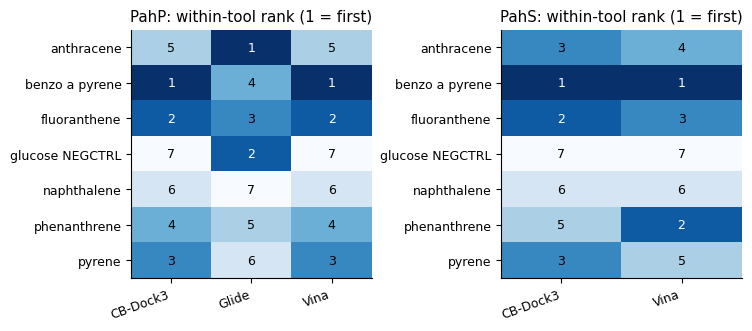

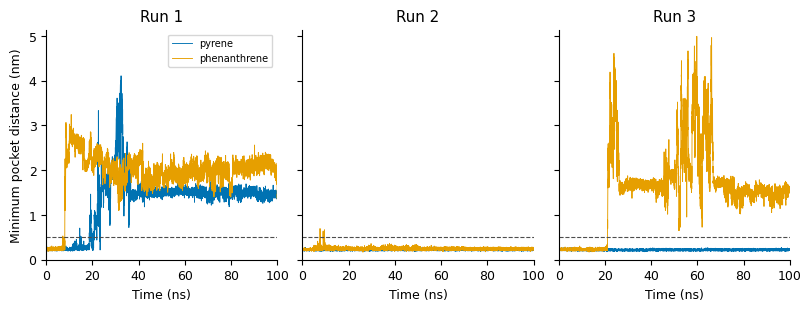

In [4]:
# Compact views state what was analysed and which completion claim is supported.
def result_view(table, input_data):
    return table.assign(**{"Input data": input_data, "Finished without more wet-lab data?": "Yes: stored computations"})
display(result_view(docking[["tool", "target", "ligand", "score", "rank"]], "Four docking JSONs"),
        result_view(contacts.round(3), "Six distance XVGs"),
        result_view(energies, "Two replicate-2 DATs"))
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.2), layout="constrained")
for ax, target in zip(axes, ["PahP", "PahS"]):
    ranks = docking[docking.target == target].pivot(index="ligand", columns="tool", values="rank")
    ranks.to_csv(OUTPUT / f"{target}_rank_plot_data.csv")
    ax.imshow(ranks, cmap="Blues_r", vmin=1, vmax=7, aspect="auto")
    ax.set_xticks(range(len(ranks.columns)), ranks.columns, rotation=20, ha="right")
    ax.set_yticks(range(len(ranks.index)), [x.replace("_", " ") for x in ranks.index])
    for i in range(len(ranks)):
        for j in range(len(ranks.columns)):
            value = ranks.iloc[i, j]
            ax.text(j, i, str(int(value)) if pd.notna(value) else "—", ha="center", va="center", color="white" if value < 3 else "black")
    ax.set_title(f"{target}: within-tool rank (1 = first)")
save_figure(fig, "docking_ranks")
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(8.0, 3.0), sharex=True, sharey=True, layout="constrained")
for ax, run in zip(axes, RUNS):
    for ligand, colour in zip(LIGANDS, [BLUE, ORANGE]):
        trace = traces[(traces.ligand == ligand) & (traces.run == run)]
        ax.plot(trace.time_ns, trace.distance_nm, color=colour, lw=0.65, label=ligand)
    ax.axhline(CONTACT_NM, color="0.3", ls="--", lw=0.8)
    ax.set(xlabel="Time (ns)", title=f"Run {run}", xlim=(0, 100))
# Fix shared limits only after all six traces have been plotted.
common_ymax = 1.03 * float(traces.distance_nm.max())
for ax in axes:
    ax.set_ylim(0, common_ymax)
axes[0].set_ylabel("Minimum pocket distance (nm)")
axes[0].legend(fontsize=7)
save_figure(fig, "pocket_distances")
plt.show()
runtime = {name: version(name) for name in ["numpy", "pandas", "matplotlib"]}
(OUTPUT / "source_manifest.json").write_text(json.dumps({"sha256": source_hashes, "snapshot_commits": SOURCE_COMMITS,
    "python": sys.version, "platform": platform.platform(), "packages": runtime}, indent=2), encoding="utf-8");

In [5]:
# Interpret the calculated values, not cached text from an earlier report.
top = docking[docking.target == "PahP"].sort_values("rank").groupby("tool", sort=True).first()
rank_text = "; ".join(f"{tool}: {row.ligand}" for tool, row in top.iterrows())
contact_text = "; ".join(f"{lig}: " + ", ".join(f"{x:.2f}%" for x in contacts[contacts.ligand == lig].contact_percent) for lig in LIGANDS)
totals = energies[energies.component == "ΔTOTAL"].set_index("ligand")
energy_difference = totals.loc["phenanthrene", "mean_kcal_mol"] - totals.loc["pyrene", "mean_kcal_mol"]
conclusion = ((f"The docking methods give different first-ranked PahP ligands ({rank_text}). "
              f"Pocket-contact fractions in runs 1-3 are {contact_text}. "
              f"Pyrene has the higher contact fraction in each run, and the selected replicate-2 MM-GBSA means favour pyrene by {energy_difference:.2f} kcal/mol."))
summary = {"title": "P-01: PAH docking ranks and pocket contact", "question": "What do the stored PAH calculations show?",
    "materials": ["Four original docking JSONs; six original distance XVGs; two original replicate-2 MM-GBSA DATs.", "Source distance script and MD/rescoring condition notes; inputs are frozen local copies."],
    "methods": ["Recalculate ranks within tool and target; do not pool scoring scales.", "Summarize strict distance <0.5 nm over each finite trace and extract reported rescoring means/SD."],
    "results": [f"{len(docking)} docking scores; PahP first ranks: {rank_text}.", f"Contact fractions: {contact_text}.", f"Replicate-2 MM-GBSA displayed-mean difference: {energy_difference:.2f} kcal/mol favouring pyrene."],
    "conclusion": conclusion,
    "limitations": [],
    "figures": [{"file": "docking_ranks.png", "caption": "Within-tool/target ranks; 1 is first. Missing methods remain absent; scores are not pooled."}, {"file": "pocket_distances.png", "caption": "All six stored finite traces; dashed line is the strict 0.5 nm criterion. Run 1 initialization differs from runs 2–3."}],
    "references": [SOURCE_URL + "/tools/autodock-vina/md", SOURCE_URL + "/tools/autodock-vina/results", f"https://github.com/Raminyazdani/igem-saarland-2026-docking-comparison/tree/{DEVELOP_COMMIT}/tools"],
    "table": {"columns": ["Ligand", "Run", "Contact (%)", "Last observed contact (ns)", "Contact at end", "Input data", "Finished without more wet-lab data?"], "rows": [[r.ligand, int(r.run), round(r.contact_percent, 3), r.last_contact_ns, bool(r.contact_at_end), "Original distance XVG", "Yes: stored computations"] for r in contacts.itertuples()]}}
summary["scope_and_assumptions"] = 'The analysis compares stored docking scores, finite initialized MD traces and one selected replicate-2 MM-GBSA result. Contact is distance below 0.5 nm. Run initialization differs, frames are correlated and CB-Dock3 shares Vina scoring. Rescoring omits entropy and uses differing salt conventions. These quantities are computational comparisons, rather than experimental affinities, equilibrium residence times or selectivity measurements.'
summary.pop("limitations", None)
(OUTPUT / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
display(Markdown("## Conclusion and interpretation\n\n" + conclusion))

## Conclusion and interpretation

The docking methods give different first-ranked PahP ligands (CB-Dock3: benzo_a_pyrene; Glide: anthracene; Vina: benzo_a_pyrene). Pocket-contact fractions in runs 1-3 are pyrene: 19.80%, 100.00%, 100.00%; phenanthrene: 8.00%, 99.68%, 21.13%. Pyrene has the higher contact fraction in each run, and the selected replicate-2 MM-GBSA means favour pyrene by 9.72 kcal/mol.